In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.datasets import load_wine
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

In [ ]:
#Load and standardize the dataset
data = load_wine(as_frame=True)

X = data.data
y = data.target

X_scaled = StandardScaler().fit_transform(X)

print("Samples:", X_scaled.shape[0])
print("Features:", list(X.columns))
print("Known classes for evaluation:", list(data.target_names))

Samples: 178
Features: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Known classes for evaluation: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]


In [ ]:
#Fit a Gaussian Mixture Model
gmm = GaussianMixture(
    n_components=3,
    covariance_type="full",
    n_init=10,
    random_state=42
)

labels = gmm.fit_predict(X_scaled)

responsibilities = gmm.predict_proba(X_scaled)

gmm_metrics = pd.Series({
    "Silhouette score": silhouette_score(X_scaled, labels),
    "Adjusted Rand index": adjusted_rand_score(y, labels),
    "Average log-likelihood": gmm.score(X_scaled),
    "Total log-likelihood": gmm.score(X_scaled) * len(X_scaled),
    "Converged": gmm.converged_,
    "EM iterations": gmm.n_iter_
})

print(gmm_metrics.round(4))

Silhouette score             0.284421
Adjusted Rand index            0.8804
Average log-likelihood      -11.73934
Total log-likelihood     -2089.602543
Converged                        True
EM iterations                       2
dtype: object


In [ ]:
#Display component weights, means, and probabilities
component_summary = pd.DataFrame(
    gmm.means_,
    columns=X.columns
)

component_summary.insert(
    0,
    "Component weight",
    gmm.weights_
)

print("Learned component parameters:")
print(component_summary.round(3).to_string(index=False))

responsibility_table = pd.DataFrame(
    responsibilities[:10],
    columns=[
        f"Component {i}"
        for i in range(gmm.n_components)
    ]
)

print("\nResponsibilities for the first ten samples:")
print(responsibility_table.round(4).to_string(index=False))

Learned component parameters:
 Component weight  alcohol  malic_acid    ash  alcalinity_of_ash  magnesium  total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity    hue  od280/od315_of_diluted_wines  proline
            0.356    0.815      -0.332  0.245             -0.676      0.637          0.822       0.897                -0.598            0.620            0.132  0.501                         0.746    1.114
            0.358   -0.942      -0.367 -0.393              0.251     -0.573         -0.033       0.081                 0.013            0.008           -0.885  0.434                         0.293   -0.781
            0.286    0.165       0.871  0.188              0.525     -0.075         -0.979      -1.216                 0.726           -0.779            0.943 -1.165                        -1.293   -0.407

Responsibilities for the first ten samples:
 Component 0  Component 1  Component 2
      1.0000       0.0000          0.0
      1.0000       0.0000  

In [ ]:
#Select the number of components using AIC and BIC
component_counts = range(1, 8)
selection_rows = []

for component_count in component_counts:
    candidate = GaussianMixture(
        n_components=component_count,
        covariance_type="full",
        n_init=10,
        random_state=42
    )

    candidate.fit(X_scaled)

    selection_rows.append({
        "Components": component_count,
        "AIC": candidate.aic(X_scaled),
        "BIC": candidate.bic(X_scaled)
    })

selection_table = pd.DataFrame(
    selection_rows
).set_index("Components")

print(selection_table.round(2))

                AIC      BIC
Components                  
1           5410.40  5741.30
2           4943.36  5608.35
3           4807.21  5806.29
4           4473.65  5806.82
5           4253.18  5920.44
6           4224.81  6226.16
7           4305.37  6640.80


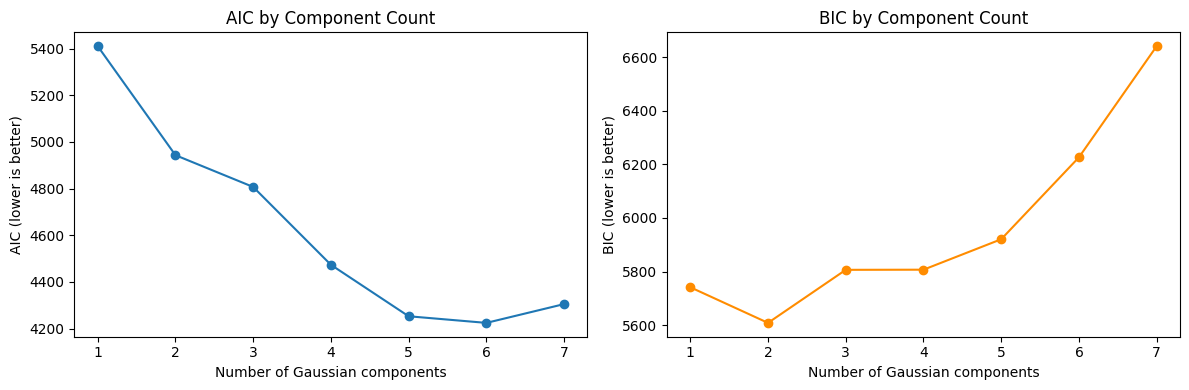

In [ ]:
#Plot AIC and BIC
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    selection_table.index,
    selection_table["AIC"],
    marker="o"
)

axes[0].set_title("AIC by Component Count")
axes[0].set_xlabel("Number of Gaussian components")
axes[0].set_ylabel("AIC (lower is better)")

axes[1].plot(
    selection_table.index,
    selection_table["BIC"],
    marker="o",
    color="darkorange"
)

axes[1].set_title("BIC by Component Count")
axes[1].set_xlabel("Number of Gaussian components")
axes[1].set_ylabel("BIC (lower is better)")

plt.tight_layout()
plt.show()


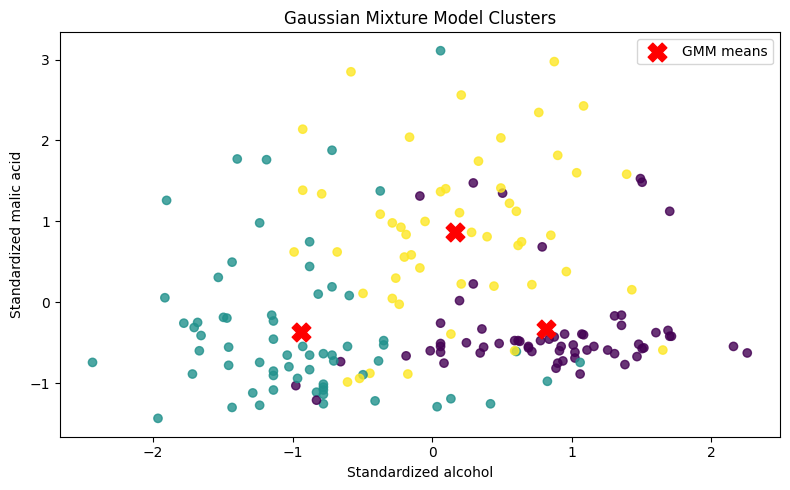

In [ ]:
#Visualize GMM clusters
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=labels,
    cmap="viridis",
    alpha=0.8
)

plt.scatter(
    gmm.means_[:, 0],
    gmm.means_[:, 1],
    marker="X",
    s=180,
    c="red",
    label="GMM means"
)

plt.xlabel("Standardized alcohol")
plt.ylabel("Standardized malic acid")
plt.title("Gaussian Mixture Model Clusters")
plt.legend()
plt.tight_layout()
plt.show()